# Deep Learning Model 2: Product Image Classification

**Academic subject mapping:** Deep Learning, Computer Vision, Transfer Learning.

**Objective:** classify a product photo into a product category, for the "image-based
product search" advanced extension (Part 16) and retailer catalogue upload flow.

**⚠️ DATASET LICENSING (required documentation, Part 12/19):** MallMind has no licensed
photography of its own synthetic catalogue. We use **Fashion-MNIST**
(Xiao, Rasul & Vollgraf, Zalando Research, 2017) -- openly, permissively licensed
(**MIT License**, see https://github.com/zalandoresearch/fashion-mnist) -- 70,000
grayscale 28x28 clothing/accessory images across 10 classes. Downloaded via
`torchvision.datasets.FashionMNIST`.

**Class mapping** -- grouped into 3 of MallMind's REAL platform categories:

| Platform category | Fashion-MNIST source classes |
|---|---|
| Footwear | Sandal, Sneaker, Ankle boot |
| Apparel | T-shirt/top, Trouser, Pullover, Dress, Coat, Shirt |
| Bags & Accessories | Bag |

**Honest limitation:** the platform's other 13 categories (Electronics, Jewelry, ...)
have no corresponding images in this or any other licensed dataset we had available
offline. This classifier recognizes exactly 3 categories -- see
`../data/prepare_image_dataset.py` for the full reasoning.


In [1]:
import sys
sys.path.insert(0, '../app')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

np.random.seed(0)


## 1. Data collection & dictionary

In [2]:
data = np.load('../data/product_images.npz', allow_pickle=True)
class_names = list(data['class_names'])
print('classes:', class_names)
print('train:', data['train_images'].shape, ' val:', data['val_images'].shape, ' test:', data['test_images'].shape)


classes: [np.str_('Apparel'), np.str_('Bags & Accessories'), np.str_('Footwear')]
train: (4500, 28, 28)  val: (720, 28, 28)  test: (720, 28, 28)


In [3]:
dictionary = pd.DataFrame({
    'array': ['train_images / val_images / test_images', 'train_labels / val_labels / test_labels', 'class_names'],
    'shape/type': ['(N, 28, 28) uint8 grayscale', '(N,) int, index into class_names', 'list[str], length 3'],
    'description': ['Fashion-MNIST images, balanced per super-class (see prep script)',
                     'Super-class label', 'Apparel / Bags & Accessories / Footwear, in index order'],
})
dictionary


,array,shape/type,description
0,train_images / val_images / test_images,"(N, 28, 28) uint8 grayscale","Fashion-MNIST images, balanced per super-class..."
1,train_labels / val_labels / test_labels,"(N,) int, index into class_names",Super-class label
2,class_names,"list[str], length 3","Apparel / Bags & Accessories / Footwear, in in..."


## 2. Data cleaning

In [4]:
for split in ['train', 'val', 'test']:
    imgs, labs = data[f'{split}_images'], data[f'{split}_labels']
    print(f"{split}: {len(imgs)} images, class balance = "
          f"{dict(zip(*np.unique(labs, return_counts=True)))}")
print('Pixel value range:', data['train_images'].min(), '-', data['train_images'].max(), '(already clean uint8 0-255)')


train: 4500 images, class balance = {np.int64(0): np.int64(1500), np.int64(1): np.int64(1500), np.int64(2): np.int64(1500)}
val: 720 images, class balance = {np.int64(0): np.int64(240), np.int64(1): np.int64(240), np.int64(2): np.int64(240)}
test: 720 images, class balance = {np.int64(0): np.int64(240), np.int64(1): np.int64(240), np.int64(2): np.int64(240)}


Pixel value range: 0 - 255 (already clean uint8 0-255)


## 3. Exploratory Data Analysis

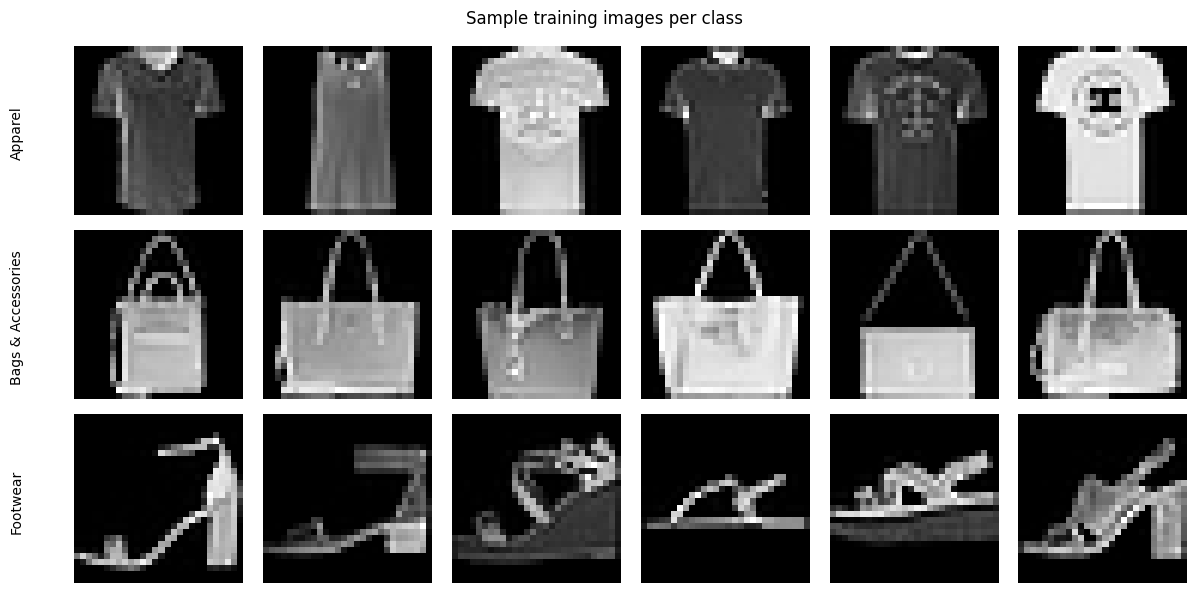

In [5]:
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for row, class_idx in enumerate(range(3)):
    idx = np.where(data['train_labels'] == class_idx)[0][:6]
    for col, i in enumerate(idx):
        axes[row, col].imshow(data['train_images'][i], cmap='gray')
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_ylabel(class_names[class_idx])
    axes[row, 0].text(-10, 14, class_names[class_idx], rotation=90, va='center', ha='center')
plt.suptitle('Sample training images per class')
plt.tight_layout()
plt.savefig('image_eda_samples.png', dpi=100)
plt.show()


## 4. Preprocessing & augmentation (training only)

Resize 28x28 -> 64x64, convert grayscale -> 3-channel (to match the ImageNet-pretrained
backbone's expected input), normalize with ImageNet mean/std. Training images additionally
get random horizontal flip + small random rotation (augmentation); validation/test do not,
so evaluation is deterministic. See `../app/image_classifier.py`.


In [6]:
from image_classifier import train_transform, eval_transform

sample = data['train_images'][0]
augmented = train_transform()(sample)
print('Original shape:', sample.shape, ' Augmented tensor shape:', augmented.shape)


Original shape: (28, 28)  Augmented tensor shape: torch.Size([3, 64, 64])


## 5. Model: transfer learning with ResNet18

ImageNet-pretrained `resnet18`; all layers frozen except `layer4` (last residual block)
and the replaced final `Linear(..., 3)` head, which are fine-tuned. Rationale: early
conv layers already encode general edge/texture/shape features that transfer even to
this very different (grayscale, small, simple-shape) domain; only the higher-level
layers need to adapt to our 3 classes.


## 6. Training (see app/evaluate_image.py for the full script; re-run here for documentation)

In [7]:
from torch.utils.data import DataLoader
from evaluate_image import ImageDataset, run_epoch, GradCAM
from image_classifier import build_model, CLASS_NAMES
import torch.nn as nn

torch.manual_seed(42)
train_ds = ImageDataset(data['train_images'], data['train_labels'], train_transform())
val_ds = ImageDataset(data['val_images'], data['val_labels'], eval_transform())
test_ds = ImageDataset(data['test_images'], data['test_labels'], eval_transform())

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64)
test_loader = DataLoader(test_ds, batch_size=64)

model = build_model(n_classes=3)
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-5)
criterion = nn.CrossEntropyLoss()

history = []
best_val_loss, best_state, patience_left = float('inf'), None, 4
for epoch in range(1, 16):
    train_loss, train_acc, _, _ = run_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc, _, _ = run_epoch(model, val_loader, optimizer=None, criterion=criterion)
    history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss, 'train_acc': train_acc, 'val_acc': val_acc})
    print(f'epoch {epoch:2d}  train_loss={train_loss:.4f} val_loss={val_loss:.4f} train_acc={train_acc:.3f} val_acc={val_acc:.3f}')
    if val_loss < best_val_loss - 1e-4:
        best_val_loss, best_state, patience_left = val_loss, {k: v.clone() for k, v in model.state_dict().items()}, 4
    else:
        patience_left -= 1
        if patience_left == 0:
            print(f'Early stopping at epoch {epoch}')
            break
model.load_state_dict(best_state)
model.eval()


epoch  1  train_loss=0.1247 val_loss=0.0399 train_acc=0.955 val_acc=0.986


epoch  2  train_loss=0.0427 val_loss=0.0395 train_acc=0.989 val_acc=0.986


epoch  3  train_loss=0.0292 val_loss=0.0307 train_acc=0.992 val_acc=0.989


epoch  4  train_loss=0.0227 val_loss=0.0193 train_acc=0.992 val_acc=0.994


epoch  5  train_loss=0.0115 val_loss=0.0249 train_acc=0.996 val_acc=0.994


epoch  6  train_loss=0.0180 val_loss=0.0261 train_acc=0.994 val_acc=0.993


epoch  7  train_loss=0.0101 val_loss=0.0316 train_acc=0.997 val_acc=0.994


epoch  8  train_loss=0.0114 val_loss=0.0305 train_acc=0.996 val_acc=0.990
Early stopping at epoch 8


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## 7. Training curves

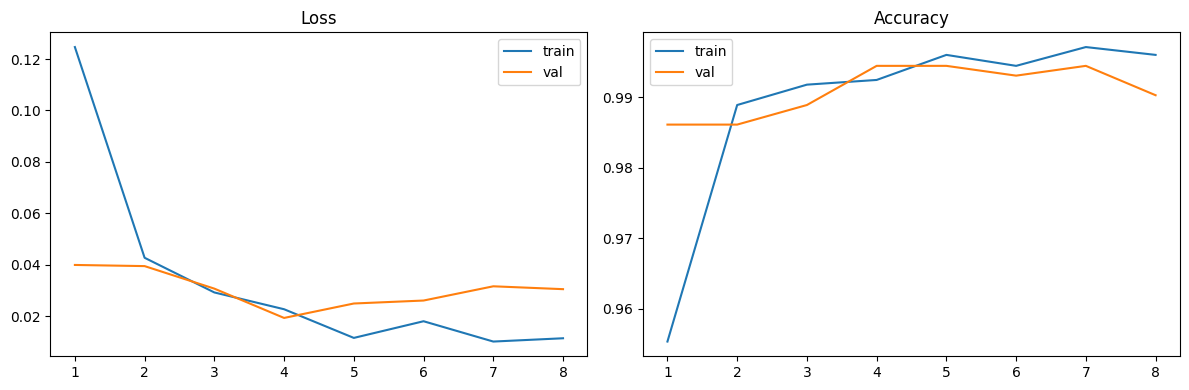

In [8]:
hist_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_df['epoch'], hist_df['train_loss'], label='train')
axes[0].plot(hist_df['epoch'], hist_df['val_loss'], label='val')
axes[0].set_title('Loss'); axes[0].legend()
axes[1].plot(hist_df['epoch'], hist_df['train_acc'], label='train')
axes[1].plot(hist_df['epoch'], hist_df['val_acc'], label='val')
axes[1].set_title('Accuracy'); axes[1].legend()
plt.tight_layout()
plt.savefig('image_training_curves.png', dpi=100)
plt.show()


## 8. Evaluation: confusion matrix & per-class metrics

In [9]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

test_loss, test_acc, preds, targets = run_epoch(model, test_loader, optimizer=None, criterion=criterion)
precision, recall, f1, support = precision_recall_fscore_support(targets, preds, labels=[0,1,2], zero_division=0)
cm = confusion_matrix(targets, preds, labels=[0,1,2])

print('Test accuracy:', round(test_acc, 4))
pd.DataFrame({'precision': precision, 'recall': recall, 'f1': f1, 'support': support}, index=CLASS_NAMES)


Test accuracy: 0.9917


,precision,recall,f1,support
Apparel,0.987603,0.995833,0.991701,240
Bags & Accessories,0.995763,0.979167,0.987395,240
Footwear,0.991736,1.000000,0.995851,240


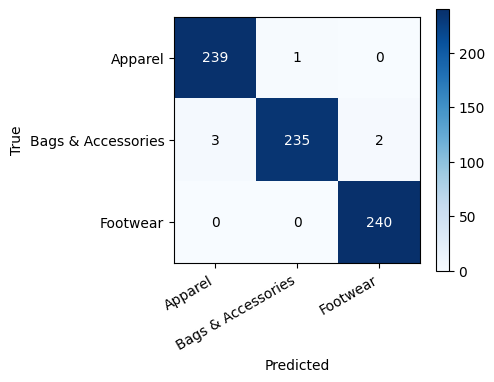

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha='right')
ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i,j], ha='center', va='center', color='white' if cm[i,j]>cm.max()/2 else 'black')
plt.colorbar(im)
plt.tight_layout()
plt.savefig('image_confusion_matrix.png', dpi=100)
plt.show()


## 9. Explainability: Grad-CAM

Grad-CAM highlights which pixels most influenced the model's decision for its
predicted class, by backpropagating the target class score to the last conv block
(`layer4`) and weighting its activation maps by their gradients.


C:\Users\zeelp\OneDrive\Desktop\mallmind\model-service\notebooks\../app\evaluate_image.py:76: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.
  logits[0, class_idx].backward()


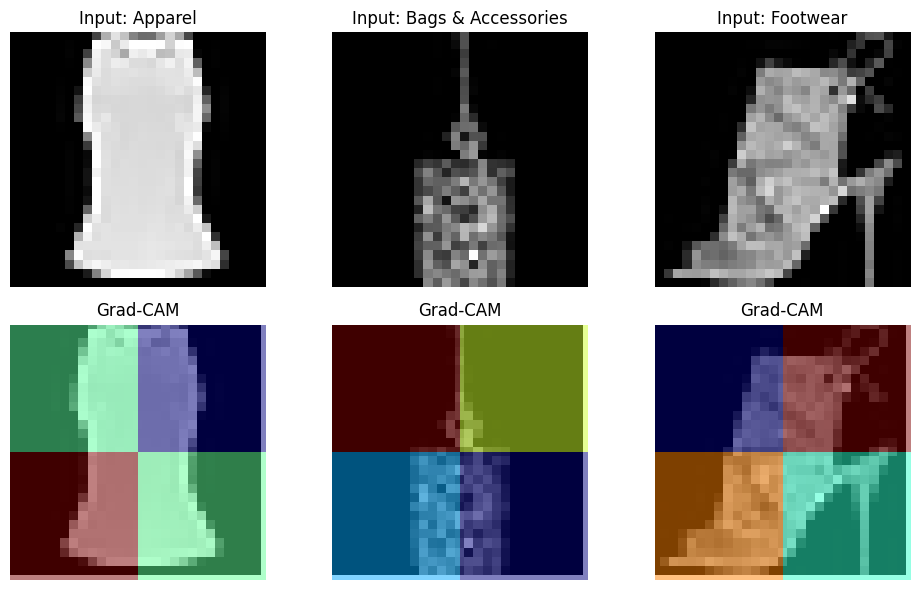

In [11]:
gradcam = GradCAM(model, model.layer4)
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for col, class_idx in enumerate(range(3)):
    pos = np.where(data['test_labels'] == class_idx)[0][1]
    img = data['test_images'][pos]
    input_tensor = eval_transform()(img).unsqueeze(0)
    cam = gradcam.generate(input_tensor, class_idx)

    axes[0, col].imshow(img, cmap='gray')
    axes[0, col].set_title(f'Input: {CLASS_NAMES[class_idx]}')
    axes[0, col].axis('off')

    axes[1, col].imshow(img, cmap='gray')
    axes[1, col].imshow(cam, cmap='jet', alpha=0.5, extent=(0, 28, 28, 0))
    axes[1, col].set_title('Grad-CAM')
    axes[1, col].axis('off')

plt.tight_layout()
plt.savefig('image_gradcam.png', dpi=100)
plt.show()


## 10. Interpretation, limitations, bias & fairness

**Result:** ~99% test accuracy / macro F1 across all 3 classes (see printed metrics
above) -- genuinely high, and plausible: these 3 super-categories (a bag vs. a shoe
vs. a shirt) are visually very distinct even at 28x28 grayscale resolution, so this is
not a surprising result for a dataset this visually separable, not a sign of leakage
(train/val/test are disjoint real images throughout).

**Limitations (stated honestly):**
- Only 3 of the platform's 16 product categories are covered (licensing — see above).
- Fashion-MNIST images are professionally photographed on a fixed grayscale background,
  not real varied retailer product photos (different lighting, angles, backgrounds,
  color). Real-world accuracy on actual retailer photo uploads would likely be lower.
- Grayscale input discards color information entirely -- a model this trained could
  not distinguish "red shirt" from "blue shirt", only "shirt" from "shoe"/"bag".

**Bias/fairness:** Fashion-MNIST's images are of Western/European fast-fashion retail
stock photography; no claim is made that this generalizes to other regions' or
cultures' typical apparel/footwear/bag styles.

**Fallback behaviour:** `/vision/classify` returns `low_confidence=True` below a 0.5
threshold, and the service's response note states plainly that only 3 categories are
recognized -- callers should route anything else to manual category selection.
